# 13 · Box–Muller y vectores normales bivariados

Cómo generar normales a partir de uniformes (método de Box–Muller), cómo construir vectores gaussianos con media y covarianza dadas, y cómo una transformación lineal deforma una densidad.

**Contenido**

1. El método de Box–Muller
2. Vectores gaussianos con covarianza dada
3. Ejes principales y covarianzas singulares
4. Transformaciones lineales de densidades

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st

rng = np.random.default_rng(2026)

## 1. El método de Box–Muller

Un vector $X=(X_1,X_2)$ es **normal estándar bivariado** si $X_1,X_2\sim N(0,1)$ son independientes. Su densidad es

$$f_{(X_1,X_2)}(x_1,x_2)=\frac{1}{\sqrt{2\pi}}e^{-x_1^2/2}\cdot\frac{1}{\sqrt{2\pi}}e^{-x_2^2/2}=\frac{1}{2\pi}e^{-\frac12(x_1^2+x_2^2)}.$$

Esta densidad solo depende de $x_1^2+x_2^2$; conviene pasar a **coordenadas polares** con el teorema de cambio de variable. La transformación

$$T:\mathbb R^2\setminus\{0\}\to(0,\infty)\times[0,2\pi),\qquad (x_1,x_2)\mapsto(r,\theta),$$

con $r^2=x_1^2+x_2^2$ y $\theta$ el ángulo polar de $(x_1,x_2)$, tiene inversa $x_1=r\cos\theta$, $x_2=r\sin\theta$ y jacobiano $r$. Sean $R=\sqrt{X_1^2+X_2^2}$ y $\Theta$ el ángulo de $X$. Entonces

$$f_{(R,\Theta)}(r,\theta)=\frac{1}{2\pi}\,r\,e^{-r^2/2}=\underbrace{\frac{1}{2\pi}}_{f_\Theta(\theta)}\cdot\underbrace{r\,e^{-r^2/2}}_{f_R(r)},$$

así que $R$ y $\Theta$ son **independientes**, $\Theta\sim\mathrm{Unif}[0,2\pi)$ y $R$ tiene la ley de **Rayleigh**. Además $D=R^2$ tiene densidad $\frac12e^{-d/2}$: $D\sim\exp(1/2)$.

Ambas leyes se simulan con una uniforme. Si $U_1,U_2\sim\mathrm{Unif}(0,1)$ son independientes:

- $\Theta:=2\pi U_1$;
- $D:=-2\ln U_2$, pues para $x>0$
$$\mathbb P(D\le x)=\mathbb P\big(\ln U_2\ge-\tfrac x2\big)=\mathbb P\big(U_2\ge e^{-x/2}\big)=1-e^{-x/2}.$$

**Teorema (Box–Muller).** Si $U_1,U_2$ son uniformes independientes en $(0,1)$, entonces

$$X_1=\sqrt{-2\ln U_2}\,\cos(2\pi U_1),\qquad X_2=\sqrt{-2\ln U_2}\,\sin(2\pi U_1)$$

son normales estándar independientes.

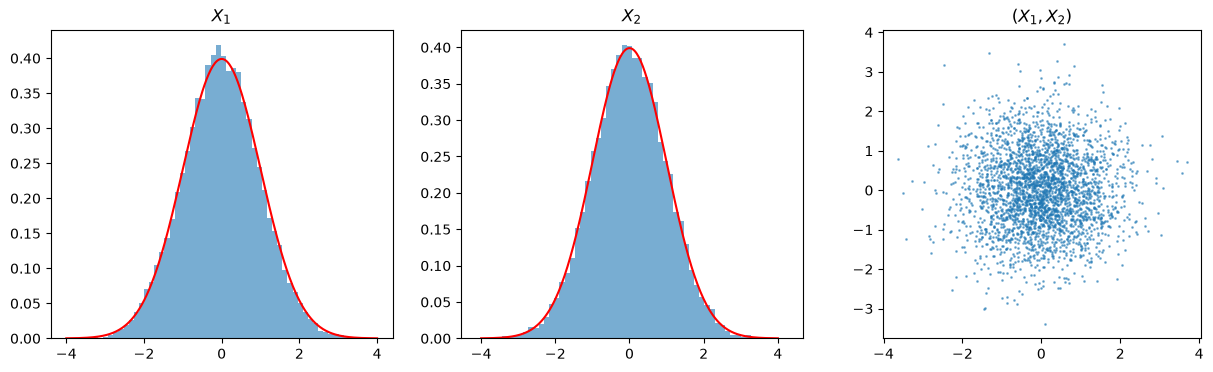

correlación muestral: 0.0039
Kolmogorov–Smirnov X_1: 0.046   X_2: 0.699


In [2]:
def box_muller(size):
    u1, u2 = rng.random(size), 1 - rng.random(size)   # u2 en (0, 1]: evita log(0)
    r = np.sqrt(-2 * np.log(u2))
    return r * np.cos(2 * np.pi * u1), r * np.sin(2 * np.pi * u1)

z1, z2 = box_muller(20_000)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
t = np.linspace(-4, 4, 300)
for ax, z, nombre in [(axes[0], z1, "$X_1$"), (axes[1], z2, "$X_2$")]:
    ax.hist(z, bins=60, density=True, alpha=0.6)
    ax.plot(t, st.norm.pdf(t), "r")
    ax.set_title(nombre)
axes[2].plot(z1[:3000], z2[:3000], ".", ms=2, alpha=0.5)
axes[2].set_aspect("equal")
axes[2].set_title("$(X_1, X_2)$")
plt.show()
print("correlación muestral:", np.corrcoef(z1, z2)[0, 1].round(4))
print("Kolmogorov–Smirnov X_1:", st.kstest(z1, "norm").pvalue.round(3), "  X_2:", st.kstest(z2, "norm").pvalue.round(3))

## 2. Vectores gaussianos con covarianza dada

Un vector $X=(X_1,\dots,X_n)$ es **gaussiano** si toda combinación lineal $\langle a,X\rangle=\sum a_iX_i$ es una variable normal (posiblemente degenerada). Sus parámetros son la media $\mu=\mathbb E[X]$ y la covarianza $\Sigma=(\operatorname{Cov}(X_i,X_j))_{ij}$; se escribe $X\sim N(\mu,\Sigma)$.

Que cada componente sea normal **no** basta para que el vector sea gaussiano; y las componentes de un vector gaussiano son independientes si y solo si $\Sigma$ es diagonal.

**Teorema.** Sean $\mu\in\mathbb R^n$ y $\Sigma\in\mathrm{Mat}_{n\times n}(\mathbb R)$ simétrica y semidefinida positiva. Existe un vector gaussiano $X\sim N(\mu,\Sigma)$.

*Construcción.* Sea $A$ con $AA^\top=\Sigma$ (por ejemplo, la factorización de Cholesky si $\Sigma$ es definida positiva, o $A=U\,\mathrm{diag}(\sqrt{s_i})$ con la descomposición espectral $\Sigma=U\,\mathrm{diag}(s_i)\,U^\top$). Si $Z\sim N(0,I_n)$, entonces $X=\mu+AZ$ es gaussiano con $\mathbb E[X]=\mu$ y $\operatorname{Cov}(X)=A\,I\,A^\top=\Sigma$.

In [3]:
mu = np.array([3.0, 4.0])
Sigma = np.array([[3.0, -1.0], [-1.0, 0.5]])

A = np.linalg.cholesky(Sigma)
Z = rng.standard_normal((2, 5000))
X = mu[:, None] + A @ Z

print("A Aᵀ =\n", A @ A.T)
print("media muestral:", X.mean(axis=1).round(3))
print("covarianza muestral:\n", np.cov(X).round(3))

A Aᵀ =
 [[ 3.  -1. ]
 [-1.   0.5]]
media muestral: [2.961 4.015]
covarianza muestral:
 [[ 2.951 -0.99 ]
 [-0.99   0.505]]


## 3. Ejes principales y covarianzas singulares

Si $\Sigma=U\,\mathrm{diag}(s_1,s_2)\,U^\top$, las columnas de $U$ son los **ejes principales** de la nube de puntos, y $\sqrt{s_i}$ es la desviación estándar a lo largo de cada eje. Las curvas de nivel de la densidad son elipses con esos ejes.

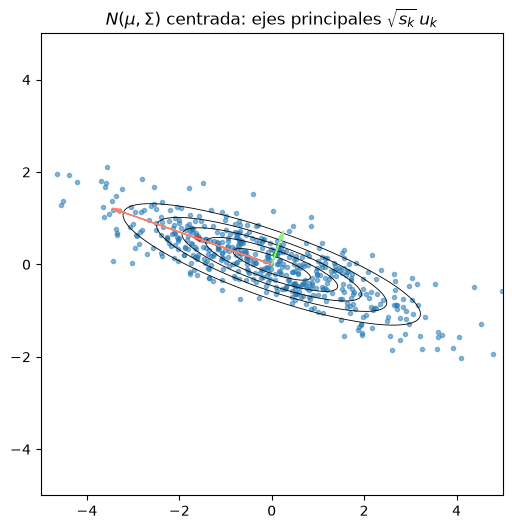

In [4]:
def dibuja_base(ax, vecs, origen=(0, 0), colores=("tab:red", "tab:green"), cabeza=0.1):
    """Dibuja las columnas de vecs como flechas desde origen."""
    for k, c in enumerate(colores):
        ax.arrow(*origen, *vecs[:, k], head_width=cabeza, head_length=2 * cabeza, color=c, zorder=10, length_includes_head=True)


U, s, _ = np.linalg.svd(Sigma)
ejes = U * np.sqrt(s)            # columna k: U[:, k] * sqrt(s_k)

fig, ax = plt.subplots(figsize=(6, 6))
X_cen = X - mu[:, None]
ax.plot(X_cen[0, :500], X_cen[1, :500], ".", alpha=0.5)
dibuja_base(ax, ejes)
dibuja_base(ax, 2 * ejes, colores=("salmon", "lightgreen"))
xx, yy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-5, 5, 200))
dens = st.multivariate_normal(np.zeros(2), Sigma).pdf(np.dstack([xx, yy]))
ax.contour(xx, yy, dens, levels=5, colors="k", linewidths=0.6)
ax.set_aspect("equal")
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)
ax.set_title(r"$N(\mu,\Sigma)$ centrada: ejes principales $\sqrt{s_k}\,u_k$")
plt.show()

Si $\Sigma$ es singular, el vector gaussiano existe pero no tiene densidad: vive en un subespacio propio. Con $\Sigma=\begin{pmatrix}1&2\\2&4\end{pmatrix}$ (de rango $1$) se tiene $X_2-\mu_2=2(X_1-\mu_1)$ casi seguramente. La factorización de Cholesky falla, pero `multivariate_normal` usa la descomposición espectral.

det = 0.0


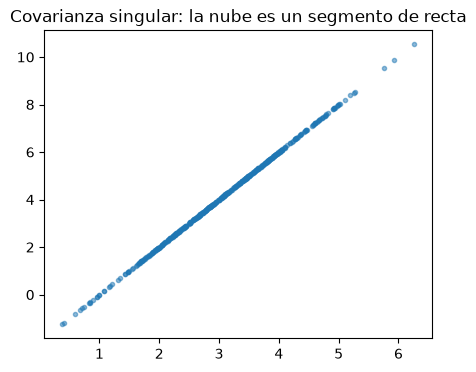

máx |(X₂ − 4) − 2(X₁ − 3)| = 1.0446022002952304e-07


In [5]:
Sigma_sing = np.array([[1.0, 2.0], [2.0, 4.0]])
print("det =", np.linalg.det(Sigma_sing))
X = rng.multivariate_normal(mean=mu, cov=Sigma_sing, size=500).T

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(X[0], X[1], ".", alpha=0.5)
ax.set_title("Covarianza singular: la nube es un segmento de recta")
plt.show()
print("máx |(X₂ − 4) − 2(X₁ − 3)| =", np.abs((X[1] - 4) - 2 * (X[0] - 3)).max())

## 4. Transformaciones lineales de densidades

La construcción $X=\mu+AZ$ es un caso del teorema de cambio de variable: si $X$ tiene densidad $f_X$ y $a$ es una matriz invertible, entonces $Y=aX$ tiene densidad

$$f_Y(y)=\frac{f_X(a^{-1}y)}{|\det a|}.$$

Además, para cualquier ley, $\mathbb E[aX]=a\,\mathbb E[X]$ y $\operatorname{Cov}(aX)=a\operatorname{Cov}(X)a^\top$.

Lo ilustramos con un vector **no gaussiano** de componentes independientes $X_0\sim\mathrm{Beta}(1,3)$ y $X_1\sim\mathrm{Beta}(2,1)$, cuya densidad es el producto de las marginales.

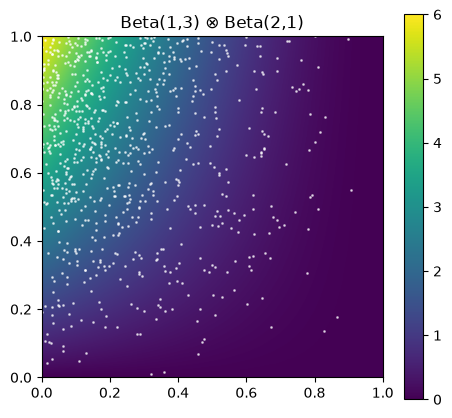

In [6]:
def beta_beta(n, a0=1, b0=3, a1=2, b1=1):
    return np.stack([rng.beta(a0, b0, n), rng.beta(a1, b1, n)])

def densidad_beta_beta(x, y, a0=1, b0=3, a1=2, b1=1):
    return st.beta.pdf(x, a0, b0) * st.beta.pdf(y, a1, b1)

xx, yy = np.meshgrid(np.linspace(0, 1, 400), np.linspace(0, 1, 400))
X = beta_beta(2000)

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(densidad_beta_beta(xx, yy), extent=[0, 1, 0, 1], origin="lower", cmap="viridis")
ax.plot(X[0, :800], X[1, :800], "w.", ms=2, alpha=0.6)
fig.colorbar(im, ax=ax)
ax.set_title("Beta(1,3) ⊗ Beta(2,1)")
plt.show()

Ahora aplicamos $a=\begin{pmatrix}1&-1\\-0.7&0.1\end{pmatrix}$. Como $\mathbb E[X]=\big(\frac14,\frac23\big)$, $\operatorname{Var}(X_0)=\frac{3}{80}$ y $\operatorname{Var}(X_1)=\frac1{18}$,

$$\mathbb E[aX]=a\begin{pmatrix}1/4\\2/3\end{pmatrix}=\begin{pmatrix}-5/12\\-13/120\end{pmatrix},\qquad \operatorname{Cov}(aX)=a\begin{pmatrix}3/80&0\\0&1/18\end{pmatrix}a^\top.$$

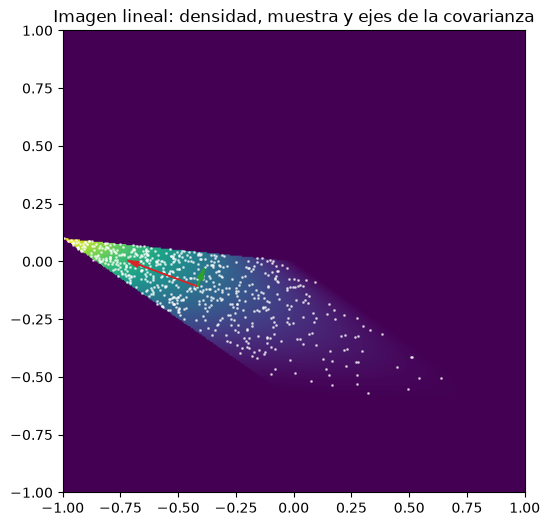

integral numérica de la densidad transformada: 1.0
media teórica: [-0.4167 -0.1083]   muestral: [-0.4279 -0.1051]
covarianza teórica:
 [[ 0.0931 -0.0318]
 [-0.0318  0.0189]] 
muestral:
 [[ 0.0917 -0.0312]
 [-0.0312  0.0188]]


In [7]:
a = np.array([[1.0, -1.0], [-0.7, 0.1]])
a_inv, det_a = np.linalg.inv(a), abs(np.linalg.det(a))


def densidad_transformada(y1, y2):
    x = a_inv @ np.stack([y1.ravel(), y2.ravel()])
    return (densidad_beta_beta(x[0], x[1]) / det_a).reshape(y1.shape)


aX = a @ beta_beta(5000)
media = a @ np.array([1 / 4, 2 / 3])
cov = a @ np.diag([3 / 80, 1 / 18]) @ a.T

y1, y2 = np.meshgrid(np.linspace(-1, 1, 400), np.linspace(-1, 1, 400))
dens = densidad_transformada(y1, y2)

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(dens, cmap="viridis", origin="lower", extent=[-1, 1, -1, 1])
ax.plot(aX[0, :600], aX[1, :600], "w.", ms=2, alpha=0.6)
U, s, _ = np.linalg.svd(cov)
dibuja_base(ax, U * np.sqrt(s), origen=media, cabeza=0.025)
ax.set_aspect("equal")
ax.set_title("Imagen lineal: densidad, muestra y ejes de la covarianza")
plt.show()

celda = (2 / 399) ** 2
print("integral numérica de la densidad transformada:", round(dens.sum() * celda, 3))
print("media teórica:", media.round(4), "  muestral:", aX.mean(axis=1).round(4))
print("covarianza teórica:\n", cov.round(4), "\nmuestral:\n", np.cov(aX).round(4))

Las componentes de $aX$ están correlacionadas aunque las de $X$ no lo estén, y $aX$ no es gaussiano: la covarianza describe la dispersión pero no la forma de la ley.

## Ejercicios

1. Demuestra que $R$ tiene densidad de Rayleigh $f_R(r)=re^{-r^2/2}$, $r>0$.
2. Construye dos variables $N(0,1)$ cuyo vector no sea gaussiano. (Sugerencia: $X_2=\varepsilon X_1$ con $\varepsilon=\pm1$ independiente de $X_1$.)
3. Verifica numéricamente que `np.linalg.cholesky` falla para la matriz singular y explica por qué.